# Backbone FundidoraPC

Define las dos arquitecturas del backbone (`base` y `plus`, con bloque de contexto dilatado) y las somete a diez pruebas: formas, activaciones, gradientes, campo receptivo, alineacion espacial, compatibilidad con la cabeza, batch real, modo train/eval y tiempo de forward.

**Entradas:** `splits/dataset.csv` (`Dataset_splits`), el manifiesto y `PengwinDetectionDataset` (`Targets_deteccion`) y `data_mha/` para el batch real de la prueba 8.

## 1. Configuracion

Rutas relativas a la raiz del repositorio y lectura de los archivos que generan los notebooks anteriores. Las definiciones compartidas se cargan por nombre desde el notebook donde viven (`definiciones_notebooks.cargar_definiciones`), sin ejecutar sus celdas de prueba.

In [3]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
import SimpleITK as sitk
import torch
import torch.nn as nn
import torch.nn.functional as F

# Raiz del repositorio: funciona si el kernel arranca en notebooks/ o en la raiz.
BASE_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))  # para importar los modulos de src/

from src.definiciones_notebooks import cargar_definiciones

SPLITS_DIR = BASE_DIR / "splits"
from src.rutas import MANIFEST_CSV
NOTEBOOKS_DIR = BASE_DIR / "notebooks"

def to_repo_relative(path):
    """Guarda rutas portables dentro del repositorio."""
    path = Path(path)
    try:
        return path.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return path.as_posix()


def resolve_repo_path(path):
    """Permite leer rutas relativas o absolutas sin romper compatibilidad."""
    path = Path(path)
    if path.is_absolute():
        return path
    return BASE_DIR / path

# Dataset curado y splits generados por Dataset_splits.ipynb
df = pd.read_csv(SPLITS_DIR / "dataset.csv", dtype={"case_id": str})
# Indice de cortes positivos generado por Targets_deteccion.ipynb
slice_manifest = pd.read_csv(MANIFEST_CSV, dtype={"case_id": str})

cargar_definiciones(NOTEBOOKS_DIR / "Ventaneo_hu.ipynb", {"load_mha", "apply_hu_window", "enhance_bone_contrast"}, destino=globals())
cargar_definiciones(NOTEBOOKS_DIR / "Targets_deteccion.ipynb", {"instance_to_semantic", "boxes_from_semantic", "letterbox_pair", "build_detection_target",
     "PengwinDetectionDataset", "detection_collate"},
                    valores={"CLASS_ID_TO_NAME", "TARGET_COLORS"}, destino=globals())

8

## 2. Definicion del backbone
Definimos dos arquitecturas para el backbone, una siendo la base y otra con ciertos ajustes para realizar una mejor extracción de la información. Luego realizamos distintas pruebas para comprobar que efectivamente funciona mejor y que la salida obtenida es igual a la esperada.

In [4]:
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NAMES = ["base", "plus"]
RESULTADOS = {n: {} for n in NAMES}   # se llena en las pruebas y se resume al final
print("torch", torch.__version__, "| dispositivo:", DEVICE)

torch 2.11.0+cu128 | dispositivo: cuda


In [5]:
class FundidoraPC(nn.Module):
    """4 bloques Conv3x3 -> BatchNorm -> ReLU -> MaxPool2x2 (version base)."""

    def __init__(self, in_channels=3):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(kernel_size=2)

        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)
        self.pool4 = nn.MaxPool2d(kernel_size=2)

        self.global_pool = nn.AdaptiveAvgPool2d(output_size=1)
        self.out_features = 256

    def _encode(self, x):
        x = self.pool1(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool2(torch.relu(self.bn2(self.conv2(x))))
        x = self.pool3(torch.relu(self.bn3(self.conv3(x))))
        # Solo 4 MaxPool en total: no agregar pooling extra.
        return self.pool4(torch.relu(self.bn4(self.conv4(x))))

    def forward(self, x):
        feature_map = self._encode(x)                                # [B, 256, H/16, W/16]
        pooled = self.global_pool(feature_map).flatten(start_dim=1)  # [B, 256]
        return pooled, feature_map



In [6]:
class FundidoraPCPlus(FundidoraPC):
    """Base + bloque de contexto a stride 16 (convs dilatadas, residual)."""
    def __init__(self, in_channels=3, dilations=(2, 4)):
        super().__init__(in_channels)
        self.dilations = tuple(dilations)
        layers = []
        for d in self.dilations:
            layers += [nn.Conv2d(256, 256, kernel_size=3, padding=d, dilation=d, bias=False),
                       nn.BatchNorm2d(256), nn.ReLU(inplace=True)]
        self.context = nn.Sequential(*layers)

    def _encode(self, x):
        feature_map = super()._encode(x)
        return feature_map + self.context(feature_map)


def build_backbone(name="base", in_channels=1):
    if name == "base":
        return FundidoraPC(in_channels=in_channels)
    if name == "plus":
        return FundidoraPCPlus(in_channels=in_channels)
    raise ValueError(f"backbone desconocido: {name!r}")


BASE_LAYERS = [(3, 1, 1), (2, 2, 1)] * 4          # (kernel, stride, dilation)
PLUS_LAYERS = BASE_LAYERS + [(3, 1, 2), (3, 1, 4)]
LAYERS = {"base": BASE_LAYERS, "plus": PLUS_LAYERS}

def theoretical_receptive_field(layers):
    r, j = 1, 1
    for k, s, d in layers:
        r += (k - 1) * d * j
        j *= s
    return r, j

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def make_models(train=False):
    out = {}
    for n in NAMES:
        torch.manual_seed(SEED)
        m = build_backbone(n, in_channels=1).to(DEVICE)
        out[n] = m.train() if train else m.eval()
    return out

MODELS = make_models()
for n, m in MODELS.items():
    RESULTADOS[n]["parametros"] = count_parameters(m)
    RESULTADOS[n]["rf_teorico"] = theoretical_receptive_field(LAYERS[n])[0]
    print(f"{n:5s} parametros = {count_parameters(m):>9,} | RF teorico = {RESULTADOS[n]['rf_teorico']} px")

base  parametros =   388,800 | RF teorico = 46 px
plus  parametros = 1,569,472 | RF teorico = 238 px


## 3. Pruebas del backbone

In [7]:
# Prueba 1 shapes
# Esperado: 256: 16, 224: 14, 192: 12

esperado_por_resolucion = {256: 16, 224: 14, 192: 12}

for name, m in MODELS.items():
    for size, hw in esperado_por_resolucion.items():
        for B in (1, 4):
            with torch.no_grad():
                pooled, fmap = m(torch.rand(B, 1, size, size, device=DEVICE))
            assert pooled.shape == (B, 256), (name, size, B, pooled.shape)
            assert fmap.shape == (B, 256, hw, hw), (name, size, B, fmap.shape)
    print(f"[{name}] shapes OK  (256->16x16, 224->14x14, 192->12x12)")

[base] shapes OK  (256->16x16, 224->14x14, 192->12x12)
[plus] shapes OK  (256->16x16, 224->14x14, 192->12x12)


In [8]:
#Prueba 2 

x = torch.rand(4, 1, 256, 256, device=DEVICE)
for name, m in MODELS.items():
    with torch.no_grad():
        pooled, fmap = m(x)
    assert torch.isfinite(pooled).all() and torch.isfinite(fmap).all()
    assert fmap.min().item() >= 0, "el mapa deberia ser >= 0 (ReLU + MaxPool)"
    std_espacial = fmap.std(dim=(2, 3)).mean().item()
    muertos = int((fmap.amax(dim=(0, 2, 3)) == 0).sum().item())
    assert std_espacial > 0
    print(f"[{name}] min={fmap.min().item():.3f} max={fmap.max().item():.3f} "
          f"media={fmap.mean().item():.3f} | std espacial media={std_espacial:.4f} "
          f"| canales muertos={muertos}/256")
    RESULTADOS[name]["canales_muertos_init"] = muertos

[base] min=0.000 max=0.159 media=0.022 | std espacial media=0.0044 | canales muertos=36/256
[plus] min=0.000 max=0.159 media=0.024 | std espacial media=0.0052 | canales muertos=0/256


In [9]:
#Prueba 3

class MiniDualHead(nn.Module):
    """Stand-in de DualHeadDetector: solo usa el primer elemento de la tupla."""
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        self.cls = nn.Linear(backbone.out_features, 3)
    def forward(self, x):
        pooled, _ = self.backbone(x)
        return self.cls(pooled)

for name, m in MODELS.items():
    with torch.no_grad():
        pooled, fmap = m(x)
        assert torch.allclose(pooled, fmap.mean(dim=(2, 3)), atol=1e-6)
        assert m.out_features == 256
        assert MiniDualHead(m).to(DEVICE)(x).shape == (4, 3)
    print(f"[{name}] pooled == mean(fmap), out_features=256, DualHead-compatible OK")

[base] pooled == mean(fmap), out_features=256, DualHead-compatible OK
[plus] pooled == mean(fmap), out_features=256, DualHead-compatible OK


In [10]:
#Prueba 4 gradientes no nulos

for name, m in make_models(train=True).items():
    m.zero_grad()
    pooled, fmap = m(torch.rand(4, 1, 256, 256, device=DEVICE))
    (fmap.mean() + pooled.mean()).backward()
    normas = {}
    for n, p in m.named_parameters():
        assert p.grad is not None, f"sin gradiente: {n}"
        assert torch.isfinite(p.grad).all(), f"gradiente no finito: {n}"
        normas.setdefault(n.split(".")[0], []).append(p.grad.norm().item() ** 2)
    print(f"[{name}] norma de gradiente por bloque:")
    for k, v in normas.items():
        print(f"    {k:8s} {np.sqrt(sum(v)):.3e}")
    assert normas["conv1"][0] > 0

[base] norma de gradiente por bloque:
    conv1    4.329e-02
    bn1      6.841e-03
    conv2    1.906e-01
    bn2      6.622e-03
    conv3    2.082e-01
    bn3      7.390e-03
    conv4    2.383e-01
    bn4      1.734e-01
[plus] norma de gradiente por bloque:
    conv1    5.231e-02
    bn1      6.977e-03
    conv2    2.163e-01
    bn2      7.339e-03
    conv3    2.313e-01
    bn3      7.460e-03
    conv4    2.585e-01
    bn4      1.734e-01
    context  1.781e-01


[base] RF empirico = 46x46 px  (teorico 46)
[plus] RF empirico = 238x238 px  (teorico 238)


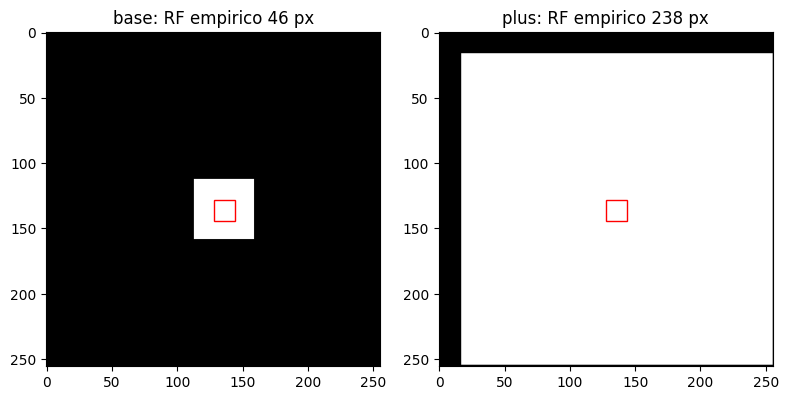

In [11]:
#Prueba 5

def rf_empirico(model, size=256, cell=(8, 8)):
    model.eval()
    xin = torch.rand(1, 1, size, size, device=DEVICE, requires_grad=True)
    _, fmap = model(xin)
    fmap[0, :, cell[0], cell[1]].sum().backward()
    g = xin.grad[0, 0].abs() > 0
    ys = g.any(1).nonzero().flatten()
    xs = g.any(0).nonzero().flatten()
    return (ys.max() - ys.min() + 1).item(), (xs.max() - xs.min() + 1).item(), g.cpu()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (name, m) in zip(axes, make_models().items()):
    ext_y, ext_x, mascara = rf_empirico(m)
    teo = RESULTADOS[name]["rf_teorico"]
    assert ext_y <= teo and ext_x <= teo, (name, ext_y, ext_x, teo)
    RESULTADOS[name]["rf_empirico"] = max(ext_y, ext_x)
    print(f"[{name}] RF empirico = {ext_y}x{ext_x} px  (teorico {teo})")
    ax.imshow(mascara, cmap="gray"); ax.set_title(f"{name}: RF empirico {max(ext_y, ext_x)} px")
    ax.add_patch(Rectangle((8 * 16, 8 * 16), 16, 16, fill=False, ec="red"))  # celda (8,8)
plt.tight_layout(); plt.show()

centroide de cambio: fila 2.5, columna 10.6  (esperado ~ fila 3, columna 11)


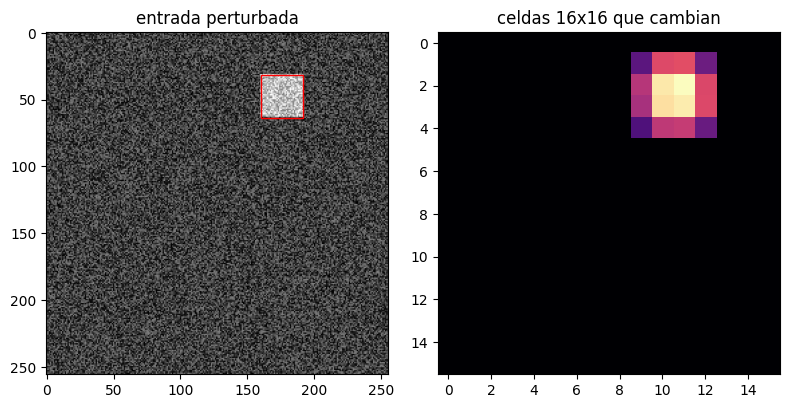

alineacion espacial OK


In [12]:
#Prueba 6

m = make_models()["base"]
xin = torch.rand(1, 1, 256, 256, device=DEVICE)
y0, y1, x0, x1 = 32, 64, 160, 192
xp = xin.clone(); xp[..., y0:y1, x0:x1] += 1.0

with torch.no_grad():
    d = (m(xp)[1] - m(xin)[1]).abs().sum(1)[0]        # [16, 16]
cambiadas = d > 1e-6
assert cambiadas.any(), "la perturbacion no modifico ninguna celda"

# celdas que pueden verse afectadas: ventana de +-23 px (RF 46) alrededor del centro de cada celda
centros = torch.arange(16, device=DEVICE) * 16 + 7.5
def toca(c, a, b, half=23 + 2):
    return (c + half >= a) & (c - half <= b - 1)
esperada = toca(centros, y0, y1)[:, None] & toca(centros, x0, x1)[None, :]
fuera = int((cambiadas & ~esperada).sum().item())
assert fuera == 0, f"{fuera} celdas cambiaron fuera de la region esperada (ejes/offset mal)"

idx = torch.arange(16, device=DEVICE, dtype=torch.float32)
cy = ((d.sum(1) * idx).sum() / d.sum()).item()
cx = ((d.sum(0) * idx).sum() / d.sum()).item()
print(f"centroide de cambio: fila {cy:.1f}, columna {cx:.1f}  (esperado ~ fila 3, columna 11)")
assert abs(cy - 3) + abs(cx - 11) < abs(cy - 11) + abs(cx - 3), "posible transposicion de ejes x/y"

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(xp[0, 0].cpu(), cmap="gray"); ax[0].set_title("entrada perturbada")
ax[0].add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="red"))
ax[1].imshow(d.cpu(), cmap="magma"); ax[1].set_title("celdas 16x16 que cambian")
plt.tight_layout(); plt.show()
print("alineacion espacial OK")

In [13]:
#Prueba 7 
#Importante para CBAM y cabeza de detección

head = nn.Conv2d(256, 1 + 4 + 3, kernel_size=1).to(DEVICE)
for name, m in MODELS.items():
    with torch.no_grad():
        _, fmap = m(torch.rand(4, 1, 256, 256, device=DEVICE))
        salida = head(fmap)
    assert salida.shape == (4, 8, 16, 16), salida.shape
    print(f"[{name}] fmap {tuple(fmap.shape)} -> salida de cabeza {tuple(salida.shape)} OK")

[base] fmap (4, 256, 16, 16) -> salida de cabeza (4, 8, 16, 16) OK
[plus] fmap (4, 256, 16, 16) -> salida de cabeza (4, 8, 16, 16) OK


<string>:42: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
<string>:47: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)


batch real: (6, 1, 256, 256) | casos: ['001', '021', '046', '063', '083', '100']
entrada: min=0.000 max=0.998
[base] correlacion mapa vs imagen reducida 16x16: +0.48, +0.73, +0.71, +0.67, +0.66, +0.50
[plus] correlacion mapa vs imagen reducida 16x16: +0.55, +0.77, +0.76, +0.71, +0.72, +0.58


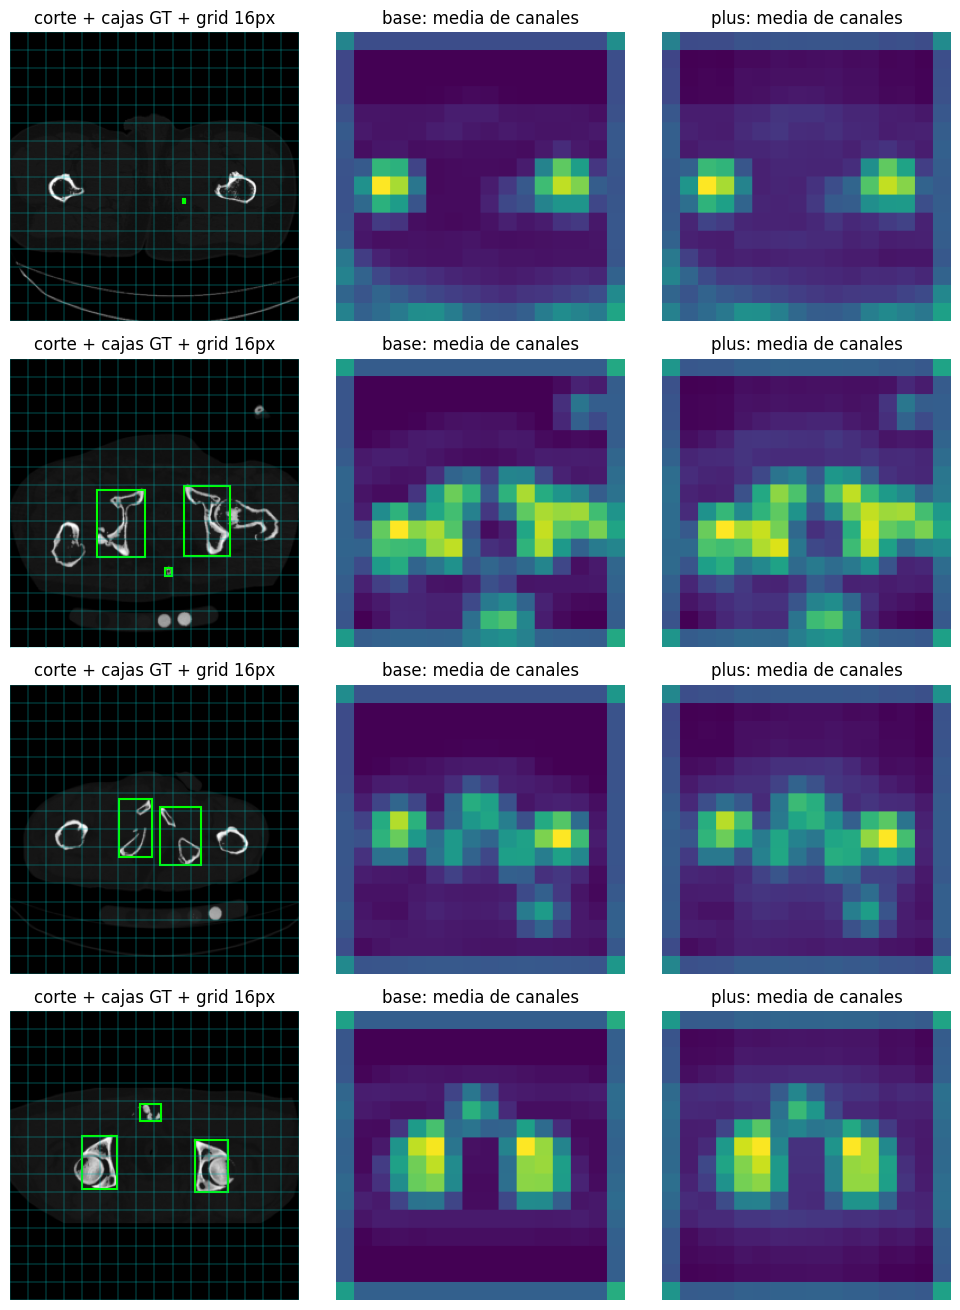

In [14]:
#Prueba 8
#Batch real

if "PengwinDetectionDataset" in globals():
    ds = PengwinDetectionDataset(split="train", image_size=256, channels=1, as_torch=True)
    idxs = np.linspace(0, len(ds) - 1, 6).astype(int)
    muestras = [ds[int(i)] for i in idxs]
    imgs = torch.stack([s[0] for s in muestras]).to(DEVICE)
    targets = [s[1] for s in muestras]
    print("batch real:", tuple(imgs.shape), "| casos:", [t["case_id"] for t in targets])
else:
    print("PengwinDetectionDataset no esta definido: usando batch sintetico")
    imgs, targets = torch.rand(6, 1, 256, 256, device=DEVICE), [None] * 6

assert imgs.shape == (6, 1, 256, 256) and imgs.dtype == torch.float32
assert torch.isfinite(imgs).all() and imgs.min() >= 0 and imgs.max() <= 1, "entrada fuera de [0,1]"
print(f"entrada: min={imgs.min().item():.3f} max={imgs.max().item():.3f}")

mapas = {}
for name, m in MODELS.items():
    with torch.no_grad():
        pooled, fmap = m(imgs)
    assert fmap.shape == (6, 256, 16, 16) and torch.isfinite(fmap).all()
    mapas[name] = fmap.mean(1)                                   # [6, 16, 16]
    ref = F.adaptive_avg_pool2d(imgs, 16)[:, 0]
    corr = [torch.corrcoef(torch.stack([mapas[name][k].flatten(), ref[k].flatten()]))[0, 1].item()
            for k in range(6)]
    print(f"[{name}] correlacion mapa vs imagen reducida 16x16: "
          + ", ".join(f"{c:+.2f}" for c in corr))

n_ver = 4
fig, axes = plt.subplots(n_ver, 3, figsize=(10, 3.3 * n_ver))
for k in range(n_ver):
    img = imgs[k, 0].cpu()
    axes[k, 0].imshow(img, cmap="gray")
    for g in range(0, 257, 16):
        axes[k, 0].axhline(g - 0.5, lw=0.3, c="c"); axes[k, 0].axvline(g - 0.5, lw=0.3, c="c")
    if targets[k] is not None:
        for b in targets[k]["boxes"].numpy():
            axes[k, 0].add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=1.5))
    axes[k, 0].set_title("corte + cajas GT + grid 16px")
    for j, name in enumerate(NAMES, start=1):
        up = F.interpolate(mapas[name][k][None, None].float(), size=256, mode="nearest")[0, 0].cpu()
        axes[k, j].imshow(up, cmap="viridis"); axes[k, j].set_title(f"{name}: media de canales")
    for a in axes[k]: a.axis("off")
plt.tight_layout(); plt.show()

In [15]:
#Prueba 9

for name in NAMES:
    torch.manual_seed(SEED)
    m = build_backbone(name, 1).to(DEVICE)
    xb = imgs[:4]
    m.train()
    with torch.no_grad():
        _, f_train = m(xb)
    m.eval()
    with torch.no_grad():
        _, f_eval = m(xb)
    rel = ((f_train - f_eval).abs().mean() / f_train.abs().mean()).item()
    print(f"[{name}] diferencia relativa train vs eval: {rel:.1%}")
print("Si el loss baja en train pero el IoU en eval no, revisar esto antes de culpar a la cabeza o a los targets.")

[base] diferencia relativa train vs eval: 98.6%
[plus] diferencia relativa train vs eval: 98.5%
Si el loss baja en train pero el IoU en eval no, revisar esto antes de culpar a la cabeza o a los targets.


In [16]:
#Prueba 10

def tiempo_forward_ms(model, B=8, n=10):
    xb = torch.rand(B, 1, 256, 256, device=DEVICE)
    model.eval()
    with torch.no_grad():
        for _ in range(3):
            model(xb)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t = time.perf_counter()
        for _ in range(n):
            model(xb)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) / n * 1000

for name, m in MODELS.items():
    RESULTADOS[name]["ms_forward_B8"] = round(tiempo_forward_ms(m), 1)

try:
    import pandas as pd
    print(pd.DataFrame(RESULTADOS).T.to_string())
except ImportError:
    for k, v in RESULTADOS.items(): print(k, v)

      parametros  rf_teorico  canales_muertos_init  rf_empirico  ms_forward_B8
base    388800.0        46.0                  36.0         46.0            6.7
plus   1569472.0       238.0                   0.0        238.0            6.4
